In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep") 

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")

In [42]:
#pistas: una fila por canción, con su género, medio y artista 
pistas = (track
    .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
    .merge(media.rename(columns={"Name": "Medio"}), on="MediaTypeId")
    .merge(album, on="AlbumId")
    .merge(artist.rename(columns={"Name": "Artista"}), on="ArtistId")
    .rename(columns={"Name": "Pista"}))
pistas["Minutos"] = pistas["Milliseconds"] / 60000
pistas["MB"] = pistas["Bytes"] / 1e6

#Las fechas llegan como texto: las convertimos a datetime
invoice["InvoiceDate"] = pd.to_datetime(invoice["InvoiceDate"])
invoice["Anio"] = invoice["InvoiceDate"].dt.year
invoice["Mes"] = invoice["InvoiceDate"].dt.month

#ventas: una fila por pista vendida
ventas = (invoice_line
    .merge(invoice, on="InvoiceId")
    .merge(track[["TrackId", "GenreId"]], on="TrackId")
    .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
    .rename(columns={"BillingCountry": "Pais"}))
ventas["Importe"] = ventas["UnitPrice"] * ventas["Quantity"]

#facturas: una fila por factura (invoice con el país renombrado)
facturas = invoice.rename(columns={"BillingCountry": "Pais"})

#Solo audio y pistas de menos de 15 min
audio = pistas[(pistas["Minutos"] < 15) & ~pistas["Medio"].str.contains("video")]
#Los 6 géneros con más pistas
top_generos = audio["Genero"].value_counts().head(6).index
musica_top = audio[audio["Genero"].isin(top_generos)]

### 1. Con el DataFrame customer, haz un countplot horizontal del número de clientes por país, ordenado de mayor a menor

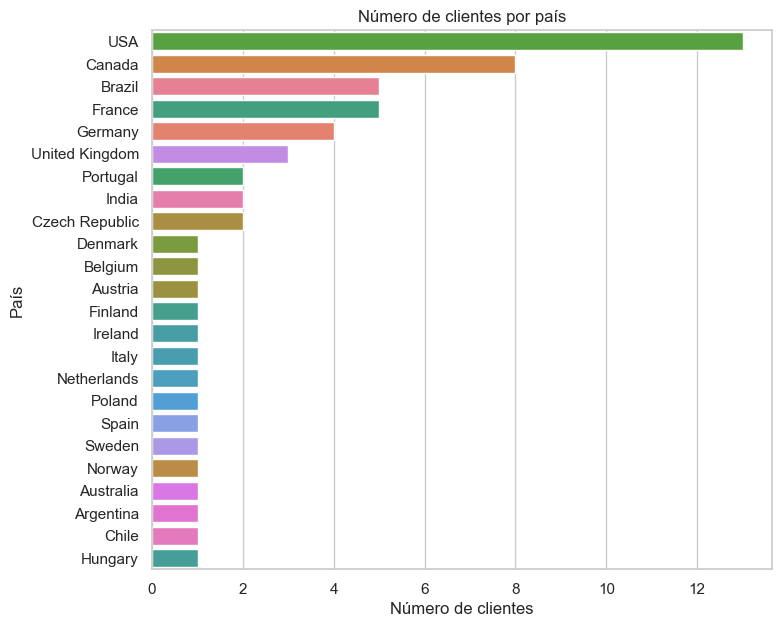

In [43]:
orden = customer["Country"].value_counts().index
plt.figure(figsize=(8, 7))
sns.countplot(data=customer, y="Country", order=orden, hue="Country", legend=False)
plt.title("Número de clientes por país"); plt.xlabel("Número de clientes"); plt.ylabel("País")
plt.show()

**Respuesta:** Estados Unidos concentra más clientes (13), seguido de Canadá (8), Brasil y Francia (5 cada uno) y Alemania (4). El resto de los países tiene 3 clientes o menos.

### 2. Haz un boxplot del Total de las facturas por país, solo para los 5 países con más ingresos. 

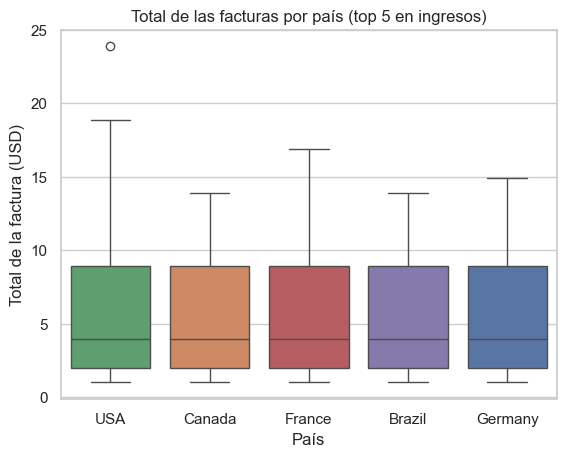

In [44]:
top5_paises = invoice.groupby("BillingCountry")["Total"].sum().nlargest(5).index
df_top5 = invoice[invoice["BillingCountry"].isin(top5_paises)]
sns.boxplot(data=df_top5, x="BillingCountry", y="Total", order=top5_paises,
            hue="BillingCountry", legend=False)
plt.title("Total de las facturas por país (top 5 en ingresos)")
plt.xlabel("País"); plt.ylabel("Total de la factura (USD)"); plt.show()

**¿Algún país tiene facturas atípicamente grandes?** Sí: **Estados Unidos**. 

### 3. Une invoice con customer (por CustomerId) y luego con employee (SupportRepId de customer corresponde a EmployeeId; usa left_on/right_on) y grafica con barplot los ingresos totales que atiende cada representante de soporte

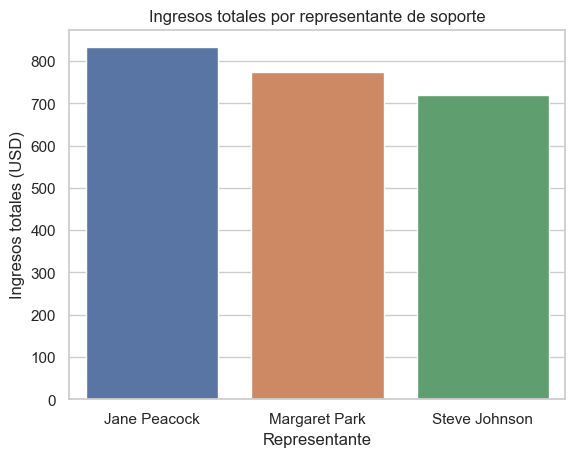

In [45]:
df3 = (invoice.merge(customer, on="CustomerId")
              .merge(employee, left_on="SupportRepId", right_on="EmployeeId"))
df3["Representante"] = df3["FirstName_y"] + " " + df3["LastName_y"]   # _y = empleado
ing_rep = df3.groupby("Representante", as_index=False)["Total"].sum().sort_values("Total", ascending=False)
sns.barplot(data=ing_rep, x="Representante", y="Total", hue="Representante", legend=False)
plt.title("Ingresos totales por representante de soporte")
plt.xlabel("Representante"); plt.ylabel("Ingresos totales (USD)")
plt.show()

**Respuesta:** Jane Peacock atiende más ingresos, luego Margaret Park y Steve Johnson.

# 4. Crea una figura de 1×2 con sharey=True: 
A la izquierda el violinplot de duración para "Rock" y "Latin"; a la derecha el stripplot de los mismos datos

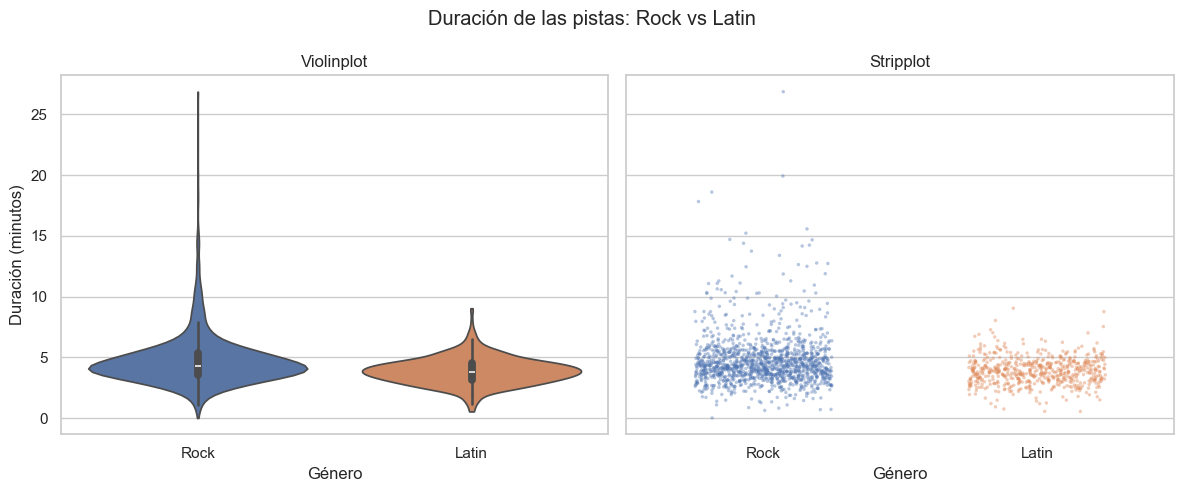

In [46]:
pg=track.merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
pg["Minutos"]=pg["Milliseconds"] / 60000
rl=pg[pg["Genero"].isin(["Rock", "Latin"])]
fig, axes=plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.violinplot(data=rl, x="Genero", y="Minutos", hue="Genero", legend=False, cut=0, ax=axes[0])
sns.stripplot(data=rl, x="Genero", y="Minutos", hue="Genero", legend=False,
              size=2.5, alpha=0.4, jitter=0.25, ax=axes[1])
axes[0].set_title("Violinplot"); axes[1].set_title("Stripplot")
axes[0].set_ylabel("Duración (minutos)"); axes[0].set_xlabel("Género"); axes[1].set_xlabel("Género")
fig.suptitle("Duración de las pistas: Rock vs Latin"); plt.tight_layout(); plt.show()

Latin es más homogéneo. El violín muestra la forma de la distribución y el stripplot deja ver cada pista, incluidos los valores extremos de Rock.

### 5. Tablero de 2×3 con seis gráficas distintas, títulos, etiquetas en español, suptitle, guardado como PNG a 200 dpi

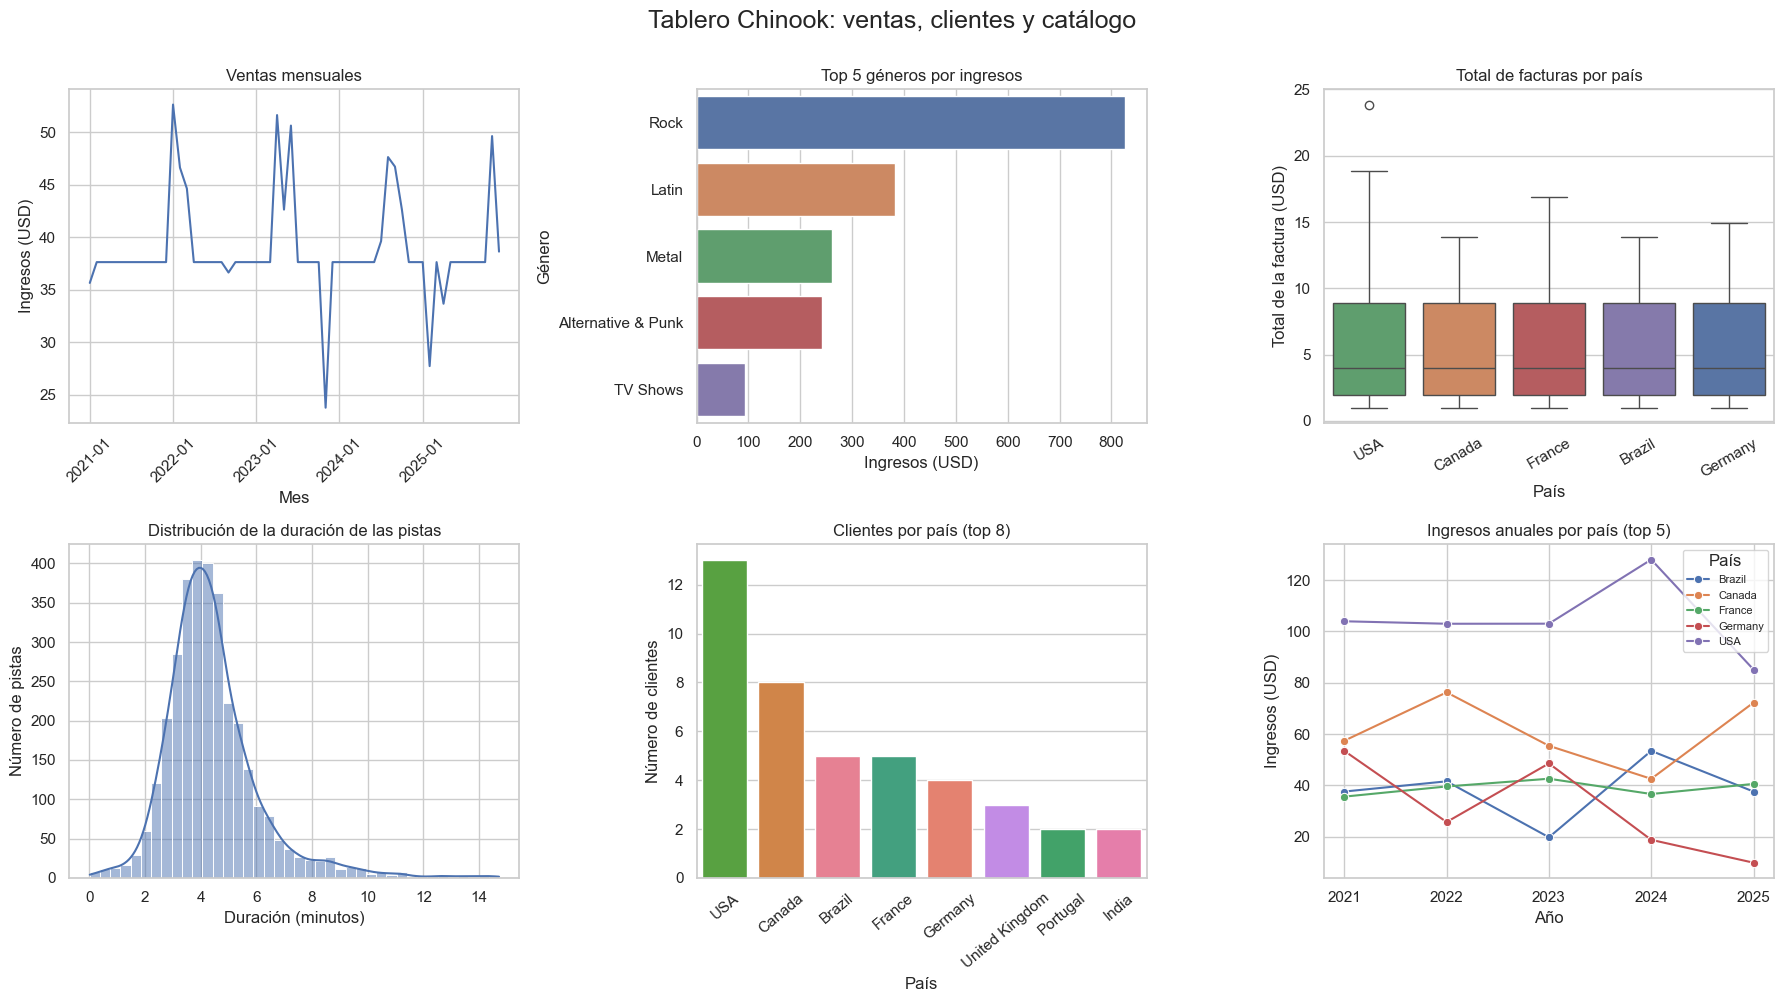

In [47]:
inv = invoice.copy()
inv["InvoiceDate"] = pd.to_datetime(inv["InvoiceDate"])
inv["Año"] = inv["InvoiceDate"].dt.year
inv["Mes_Año"] = inv["InvoiceDate"].dt.to_period("M").astype(str)

ventas_mes = inv.groupby("Mes_Año")["Total"].sum().reset_index()

lineas = (invoice_line.merge(track, on="TrackId", suffixes=("", "_trk"))
                      .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId"))
lineas["Monto"] = lineas["UnitPrice"] * lineas["Quantity"]
top_gen = lineas.groupby("Genero")["Monto"].sum().nlargest(5).reset_index()

top5_p = inv.groupby("BillingCountry")["Total"].sum().nlargest(5).index
ing_pais = inv[inv["BillingCountry"].isin(top5_p)]

pistas_min = track.assign(Minutos=track["Milliseconds"] / 60000)
pistas_min = pistas_min[pistas_min["Minutos"] < 15]

ing_año_pais = (ing_pais.groupby(["Año", "BillingCountry"], as_index=False)["Total"].sum())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1) Lineplot: ventas mensuales
sns.lineplot(data=ventas_mes, x="Mes_Año", y="Total", ax=axes[0, 0])
axes[0, 0].set_title("Ventas mensuales")
axes[0, 0].set_xlabel("Mes")
axes[0, 0].set_ylabel("Ingresos (USD)")
axes[0, 0].set_xticks(range(0, len(ventas_mes), 12))
axes[0, 0].set_xticklabels(ventas_mes["Mes_Año"][::12], rotation=45)

# 2) Barplot horizontal: top 5 géneros por ingresos
sns.barplot(data=top_gen, y="Genero", x="Monto", hue="Genero", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Top 5 géneros por ingresos")
axes[0, 1].set_xlabel("Ingresos (USD)")
axes[0, 1].set_ylabel("Género")

# 3) Boxplot: facturas por país (top 5)
sns.boxplot(data=ing_pais, x="BillingCountry", y="Total", order=top5_p,
            hue="BillingCountry", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("Total de facturas por país")
axes[0, 2].set_xlabel("País")
axes[0, 2].set_ylabel("Total de la factura (USD)")
axes[0, 2].tick_params(axis="x", rotation=30)

# 4) Histplot: duración de las pistas
sns.histplot(data=pistas_min, x="Minutos", bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Distribución de la duración de las pistas")
axes[1, 0].set_xlabel("Duración (minutos)")
axes[1, 0].set_ylabel("Número de pistas")

# 5) Countplot: clientes por país (top 8)
top8 = customer["Country"].value_counts().head(8).index
sns.countplot(data=customer, x="Country", order=top8, hue="Country", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Clientes por país (top 8)")
axes[1, 1].set_xlabel("País")
axes[1, 1].set_ylabel("Número de clientes")
axes[1, 1].tick_params(axis="x", rotation=40)

# 6) Lineplot con hue: ingreso anual de los top 5 países
sns.lineplot(data=ing_año_pais, x="Año", y="Total", hue="BillingCountry",
             marker="o", ax=axes[1, 2])
axes[1, 2].set_title("Ingresos anuales por país (top 5)")
axes[1, 2].set_xlabel("Año")
axes[1, 2].set_ylabel("Ingresos (USD)")
axes[1, 2].set_xticks(sorted(inv["Año"].unique()))
axes[1, 2].legend(title="País", fontsize=8)

fig.suptitle("Tablero Chinook: ventas, clientes y catálogo", fontsize=18, y=1.0)
plt.tight_layout()
fig.savefig("tablero_chinook.png", dpi=200, bbox_inches="tight")
plt.show()

### 6. Reproduce el heatmap de país × año, pero con el número de facturas en lugar del ingreso (aggfunc="count"). ¿Cambia la historia?

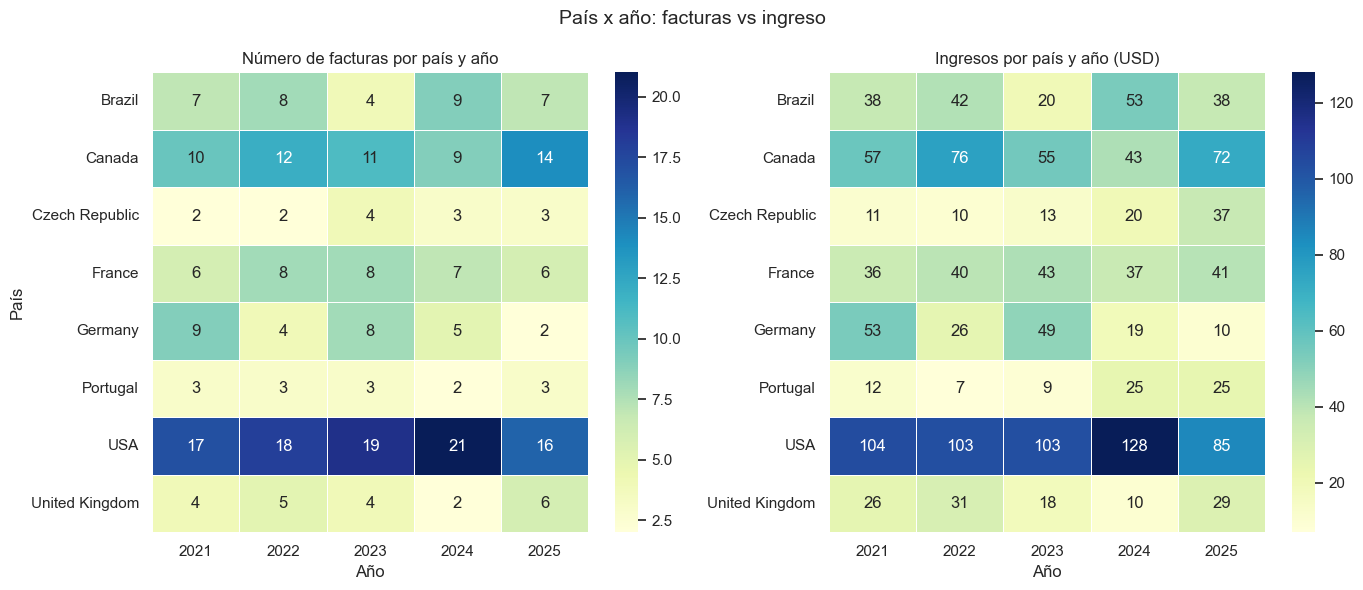

In [48]:
top_paises = facturas.groupby("Pais")["Total"].sum().nlargest(8).index
base = facturas[facturas["Pais"].isin(top_paises)]

tabla_n = base.pivot_table(index="Pais", columns="Anio", values="Total", aggfunc="count")
tabla_ing = base.pivot_table(index="Pais", columns="Anio", values="Total", aggfunc="sum")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(tabla_n, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5, ax=axes[0])
axes[0].set_title("Número de facturas por país y año")
axes[0].set_xlabel("Año"); axes[0].set_ylabel("País")

sns.heatmap(tabla_ing.loc[tabla_n.index], annot=True, fmt=".0f", cmap="YlGnBu",
            linewidths=0.5, ax=axes[1])
axes[1].set_title("Ingresos por país y año (USD)")
axes[1].set_xlabel("Año"); axes[1].set_ylabel("")

fig.suptitle("País x año: facturas vs ingreso", fontsize=14)
fig.tight_layout()
plt.show()

**¿Cambia la historia?** En lo esencial **no**. En ambos mapas EE. UU. y Canadá dominan todos los años, y Francia, Brasil y Alemania siguen detrás. 